# EDA
### 데이터 개요
- **데이터 배경**: 가상 MMORPG **Astrasia Online** 서비스 데이터
- **데이터 기간**: 2026-07-01 ~ 2026-09-28 (90일)
- **분석 대상 테이블**
  - `users.csv`: 유저 정보
  - `daily_activity.csv`: 일별 접속, 플레이타임, 골드, 아이템
  - `funnel_events.csv`: 성장 퍼널 이벤트
  - `payments.csv`: 결제 내역
- **분석 대상 유저 수**: 34,000명

### 용어 설명
- 유저는 `user_id` 단위이며, 한 사람이 여러 계정을 가지더라도 `user_id`당 한 명의 유저로 간주합니다.

### 목차
1. 환경설정 및 데이터 확인
2. 결측값, 중복값, 이상치 확인
3. 유저 구성
4. DAU, WAU
5. 신규 유저 유입과 리텐션
6. 성장 퍼널과 병목 구간
7. 매출
8. 일별 플레이타임, 골드, 아이템

## 1. 환경설정 및 데이터 확인

In [1]:
# 환경 설정
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest

# csv 파일 불러오기
users = pd.read_csv("../data/users.csv", parse_dates=["signup_date"])
daily = pd.read_csv("../data/daily_activity.csv", parse_dates=["date"])
events = pd.read_csv("../data/funnel_events.csv", parse_dates=["event_time"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["paid_at"])

In [2]:
# 지수 표시 해제 및 1,000 단위 쉼표 표시
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
# 테이블 확인
tables = {"users": users, "daily": daily, "events": events, "payments": payments}

for name, df in tables.items():
    print(f"[{name}]  {df.shape[0]:,}행 x {df.shape[1]}열")
    display(df.head(3))
    print()

[users]  34,000행 x 5열


,user_id,signup_date,country,platform,device_id
0,1,2025-07-01,JP,Mobile,DVE9166407B5
1,2,2025-07-01,KR,PC,DV1FAFC2BAAC
2,3,2025-07-01,KR,PC,DVDC9D892BDA



[daily]  268,799행 x 7열


,user_id,date,sessions,playtime_min,level,gold_earned,items_acquired
0,4,2026-07-01,4,428.10,55,90928,222
1,4,2026-07-02,3,433.30,56,131601,241
2,4,2026-07-03,5,345.80,56,119083,179



[events]  23,597행 x 3열


,user_id,event,event_time
0,4,reach_lv60,2026-07-18 12:08:58
1,5,guild_join,2026-09-09 23:21:58
2,6,reach_lv45,2026-07-10 13:23:44



[payments]  2,917행 x 3열


,user_id,paid_at,amount_krw
0,85,2026-08-17 22:27:46,5500
1,396,2026-09-03 23:55:39,33000
2,428,2026-09-02 21:49:16,33000


## 2. 결측값, 중복값, 이상치 확인

### 2-1. 결측값, 중복값

In [4]:
# 결측값, 중복값 확인

for name, df in tables.items():
    # 결측값
    n_missing = df.isna().sum().sum()

    # 중복값
    n_duplicated = df.duplicated().sum()

    print(f"[{name}]")
    print(f"결측값 수: {n_missing:,}")
    print(f"중복값 수: {n_duplicated:,}")
    print()

[users]
결측값 수: 0
중복값 수: 0

[daily]
결측값 수: 0
중복값 수: 0

[events]
결측값 수: 0
중복값 수: 0

[payments]
결측값 수: 0
중복값 수: 0



In [5]:
# users 테이블 user_id 중복값 확인
print(f"users 테이블 user_id 중복 수: {users['user_id'].duplicated().sum()}")

# events 테이블 user_id, event 조합 중복 확인
print(f"events 테이블 (user_id, event) 중복 수: {events.duplicated(subset=['user_id', 'event']).sum()}")

users 테이블 user_id 중복 수: 0
events 테이블 (user_id, event) 중복 수: 0


### 2-2. 이상치

In [6]:
# 이상치 확인

# 테이블별 기초통계량 확인
for name, df in tables.items():
    print(f"[{name}]")
    display(df.describe())

[users]


,user_id,signup_date
count,"34,000.00",34000
mean,"17,000.50",2026-02-02 23:26:19.764706
min,1.00,2025-07-01 00:00:00
25%,"8,500.75",2025-10-09 00:00:00
50%,"17,000.50",2026-01-31 00:00:00
75%,"25,500.25",2026-05-28 00:00:00
max,"34,000.00",2026-09-28 00:00:00
std,"9,815.10",NaN


[daily]


,user_id,date,sessions,playtime_min,level,gold_earned,items_acquired
count,"268,799.00",268799,"268,799.00","268,799.00","268,799.00","268,799.00","268,799.00"
mean,"19,330.09",2026-08-15 01:54:10.632628,3.14,221.77,47.72,"37,011.91",55.01
min,4.00,2026-07-01 00:00:00,1.00,5.00,2.00,111.00,0.00
25%,"13,482.00",2026-07-24 00:00:00,2.00,92.40,39.00,"12,793.00",9.00
50%,"20,787.00",2026-08-15 00:00:00,3.00,152.10,54.00,"26,219.00",20.00
75%,"25,905.00",2026-09-06 00:00:00,4.00,214.80,60.00,"47,062.00",39.00
max,"34,000.00",2026-09-28 00:00:00,14.00,"1,439.70",60.00,"1,223,864.00","1,284.00"
std,"8,255.81",NaN,1.86,269.05,14.75,"38,331.48",108.19


[events]


,user_id,event_time
count,"23,597.00",23597
mean,"25,817.35",2026-08-10 20:05:31.538331
min,4.00,2026-07-01 00:35:27
25%,"22,561.00",2026-07-21 23:41:25
50%,"29,154.00",2026-08-09 13:08:40
75%,"31,287.00",2026-08-28 20:37:03
max,"33,999.00",2026-09-28 23:59:24
std,"8,104.87",NaN


[payments]


,user_id,paid_at,amount_krw
count,"2,917.00",2917,"2,917.00"
mean,"19,216.60",2026-08-16 08:48:39.634556,"40,568.02"
min,85.00,2026-07-01 10:09:57,"1,100.00"
25%,"13,216.00",2026-07-25 18:46:00,"11,000.00"
50%,"20,477.00",2026-08-16 22:20:50,"33,000.00"
75%,"25,680.00",2026-09-06 17:31:33,"55,000.00"
max,"33,936.00",2026-09-28 23:59:37,"110,000.00"
std,"8,047.06",NaN,"34,216.61"


* 플레이타임, 골드 획득량, 아이템 획득량에서 mean 이랑 중앙값이 차이가 큰 것을 발견
* 헤비 유저의 영향일 수도 있으나, 봇/어뷰저의 영향이 있을 수 있음을 감지

In [7]:
# 이벤트 종류 확인
events["event"].unique()

<ArrowStringArray>
[       'reach_lv60',        'guild_join',        'reach_lv45',
        'reach_lv30', 'tutorial_complete',        'reach_lv10',
     'first_dungeon']
Length: 7, dtype: str

In [8]:
# 이벤트 달성 순서가 뒤죽박죽인 유저 확인

# 이벤트 달성 순서 (guild_join은 제외)
order = ["tutorial_complete", "reach_lv10", "first_dungeon",
         "reach_lv30", "reach_lv45", "reach_lv60"]

e = events[events["event"].isin(order)].copy()
e["step"] = e["event"].map({name: i for i, name in enumerate(order)})   # 단계 번호 0~5

# 유저별로 시간순 정렬한 뒤, 단계 번호가 계속 커지는지 확인
e = e.sort_values(["user_id", "event_time", "step"])
is_ordered = e.groupby("user_id")["step"].apply(lambda s: s.is_monotonic_increasing)

print(f"순서가 뒤바뀐 유저: {(~is_ordered).sum()}명")

순서가 뒤바뀐 유저: 0명


In [9]:
# 시트별 user_id 정합성 확인

# users의 user_id 집합
user_ids = set(users["user_id"])

# 비교할 테이블
tables = {
    "daily": daily,
    "events": events,
    "payments": payments,
}

# users에 없는 user_id 수
print("[테이블별 users에 없는 user_id 수]")
for name, df in tables.items():
    sheet_ids = set(df["user_id"])
    missing_in_users = sheet_ids - user_ids
    print(f"{name}: {len(missing_in_users):,}개")

[테이블별 users에 없는 user_id 수]
daily: 0개
events: 0개
payments: 0개


## 3. 유저 구성

In [10]:
# device_id별 계정 수
accounts_per_device = users.groupby("device_id")["user_id"].nunique()

# 기기 하나 당 계정 수 & 해당 기기 수
print(accounts_per_device.value_counts().sort_index())

# 2개 이상 계정을 쓰는 기기
multi = accounts_per_device[accounts_per_device >= 2]

multi_device_cnt = len(multi)
total_device_cnt = len(accounts_per_device)

print(f"\n2개 이상의 계정을 쓰는 기기 수: {multi_device_cnt:,}개 (전체 기기 {total_device_cnt:,}개 중 {multi_device_cnt / total_device_cnt * 100:.1f}%)")
print(f"그 기기에 속한 계정 수: {multi.sum():,}개")

user_id
1     33091
2        43
3        39
4        44
5         2
6         7
7         7
8         8
9         5
10        8
11        1
15        2
17        2
20        2
21        1
24        1
26        2
28        1
Name: count, dtype: int64

2개 이상의 계정을 쓰는 기기 수: 175개 (전체 기기 33,266개 중 0.5%)
그 기기에 속한 계정 수: 909개


In [11]:
# country, platform 점유율 확인

for col in ["country", "platform"]:
    counts = users[col].value_counts()
    share = counts / counts.sum() * 100

    result = pd.DataFrame({
        "users": counts,
        "share(%)": share.round(2)
    })

    print(f"[{col}]")
    display(result)

[country]


,users,share(%)
country,,
KR,15307,45.02
JP,6889,20.26
US,5982,17.59
TW,3409,10.03
OTHER,2413,7.10


[platform]


,users,share(%)
platform,,
PC,20582,60.54
Mobile,13418,39.46


## 4. DAU, WAU
**분석 대상**: 전체 유저 대상

In [12]:
# DAU: 날짜별 유니크 접속 유저
dau = daily.groupby("date")["user_id"].nunique().reset_index(name="dau")
dau.head()

,date,dau
0,2026-07-01,2410
1,2026-07-02,2619
2,2026-07-03,2516
3,2026-07-04,2862
4,2026-07-05,2818


In [13]:
# 접속일이 속한 주의 월요일
week = (daily["date"] - pd.to_timedelta(daily["date"].dt.weekday, unit="D")).rename("week")

# WAU 표: 주(월요일 시작)별 유니크 접속 유저
wau = daily.groupby(week).agg(wau=("user_id", "nunique"), days=("date", "nunique")).reset_index()
wau = wau[wau["days"] == 7].drop(columns="days")     # 7일이 다 채워진 주만
wau

,week,wau
1,2026-07-06,7257
2,2026-07-13,7374
3,2026-07-20,9256
4,2026-07-27,8091
5,2026-08-03,7856
6,2026-08-10,8553
7,2026-08-17,9039
8,2026-08-24,8174
9,2026-08-31,7599
10,2026-09-07,8671


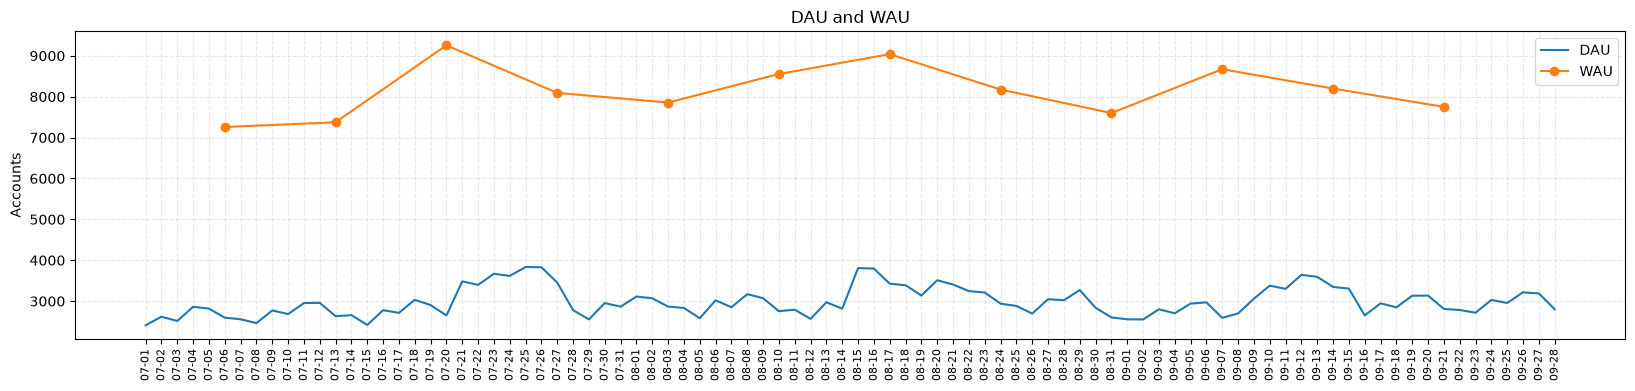

In [14]:
# 시각화
fig, ax = plt.subplots(figsize=(20, 4))

ax.plot(dau["date"], dau["dau"], label="DAU")
ax.plot(wau["week"], wau["wau"], marker="o", label="WAU")
ax.set_title("DAU and WAU")
ax.set_ylabel("Accounts")
ax.legend()
ax.grid(alpha=0.3, linestyle="--")

ax.set_xticks(dau["date"])
ax.set_xticklabels(dau["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

In [15]:
# 프로모션 아닌 기간 vs 프로모션 기간별 일평균 DAU

# 일자별 DAU (날짜를 인덱스로)
dau_s = dau.set_index("date")["dau"]

# 프로모션 및 업데이트 기간 (시작일, 종료일)
periods = {
    "여름 축제 1부": ("2026-07-21", "2026-07-27"),
    "여름 축제 2부": ("2026-08-15", "2026-08-21"),
    "성장 개편 업데이트 이후 핫픽스 전": ("2026-08-30", "2026-09-07"),
    "핫픽스일": ("2026-09-08", "2026-09-08"),
    "복귀 지원 이벤트": ("2026-09-09", "2026-09-15"),
    "복귀 지원 이벤트 종료 후": ("2026-09-16", "2026-09-28"),
}

# 기간별 일평균 DAU
rows = []
event_mask = pd.Series(False, index=dau_s.index)    # 위 기간에 해당하는 날짜 표시

for name, (start, end) in periods.items():
    in_period = (dau_s.index >= pd.Timestamp(start)) & (dau_s.index <= pd.Timestamp(end))
    event_mask = event_mask | in_period

    rows.append({
        "구분": name,
        "기간": f"{start[5:]} ~ {end[5:]}",
        "일평균 DAU": round(dau_s[in_period].mean())
    })

# 프로모션 아닌 기간: 위 기간과 핫픽스일(9/8)을 제외한 나머지 날짜
hotfix_date = pd.Timestamp("2026-09-08")
non_promo_mask = ~event_mask & (dau_s.index != hotfix_date)

rows.insert(0, {
    "구분": "프로모션 아닌 기간",
    "기간": "그 외 기간",
    "일평균 DAU": round(dau_s[non_promo_mask].mean())
})

dau_by_period = pd.DataFrame(rows).set_index("구분")

# 프로모션 아닌 기간(평시) 대비 증감률(%)
base_dau = dau_by_period.loc["프로모션 아닌 기간", "일평균 DAU"]
dau_by_period["평시 대비(%)"] = ((dau_by_period["일평균 DAU"] / base_dau - 1) * 100).round(1)

display(dau_by_period.style.format({"일평균 DAU": "{:,.0f}", "평시 대비(%)": "{:+.1f}%"}))

,기간,일평균 DAU,평시 대비(%)
구분,,,
프로모션 아닌 기간,그 외 기간,"2,825",+0.0%
여름 축제 1부,07-21 ~ 07-27,"3,612",+27.9%
여름 축제 2부,08-15 ~ 08-21,"3,497",+23.8%
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,"2,728",-3.4%
핫픽스일,09-08 ~ 09-08,"2,699",-4.5%
복귀 지원 이벤트,09-09 ~ 09-15,"3,376",+19.5%
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,"2,939",+4.0%


### **요점**
- **여름 축제 1부 기간(7/21~7/27)** : 일평균 DAU가 평시 대비 +27.9%로, 분석 기간 중 유저의 반응이 가장 높았음.
- **여름 축제 2부 기간(8/15~8/21)**: 평시 대비 +23.8%로, 여름 축제 1부와 같은 내용의 프로모션임에도 높은 반응이 나타남.
- **성장 개편 업데이트(8/30) 이후**: 핫픽스(9/8)까지 평시보다 낮은 DAU(평시 대비 -3.4%)가 이어졌음. 복귀 지원 이벤트 기간(9/9~9/15)에 DAU가 평시 대비 +19.5%로 회복되었고, 이후 일 3,000명 전후로 유지됨.
  - 업데이트에서 필드 사냥 경험치를 하향했고 핫픽스에서 하향폭을 완화했는데, 이후 DAU가 회복되어 필드 사냥 경험치 하향이 유저 접속률에 영향을 줬을 가능성이 있음.  
    다만 핫픽스 다음 날 복귀 지원 이벤트가 시작되어, 이벤트의 영향일 가능성도 있음.
  - 복귀 지원 이벤트 기간에 DAU의 복귀 유저 비율이 늘었는지, 아니면 기존 유저가 늘었는지에 따라 핫픽스의 효과를 추측 가능할 것으로 생각되어, 별도 프로모션 분석 노트북에서 확인 예정.
  - 업데이트 및 핫픽스에 대한 유저 의견은 온라인 포럼 등을 통한 추가 확인이 필요함.

## 5. 신규 유저 유입과 리텐션
**분석 대상**: 데이터 기간 동안 신규 가입자

### 리텐션 기준
- **일 리텐션**: 가입 후 `n`일째 되는 날 접속 기록이 있는 유저는 카운트
- **주 리텐션**: 가입 후 `n`주차 접속 기록이 1회 이상 있는 유저는 카운트
    - 첫 주의 시작은 `월요일`으로 함.

### 5-1. 신규 유저(가입자) 추이

In [16]:
obs_start = daily["date"].min()                       # 데이터 시작일 (신규 가입 기준)
obs_end = daily["date"].max()                         # 데이터 종료일

new_users = users[users["signup_date"] >= obs_start].copy()  # 신규 가입자 정의
new_users_cnt = len(new_users)                               # 신규 가입자 수

In [17]:
# 일별 신규 가입자 수
new_users_daily = (users[users["signup_date"] >= obs_start]
                   .groupby("signup_date")["user_id"].nunique()
                   .reset_index(name="new_users"))

new_users_daily.head()

,signup_date,new_users
0,2026-07-01,53
1,2026-07-02,50
2,2026-07-03,59
3,2026-07-04,59
4,2026-07-05,55


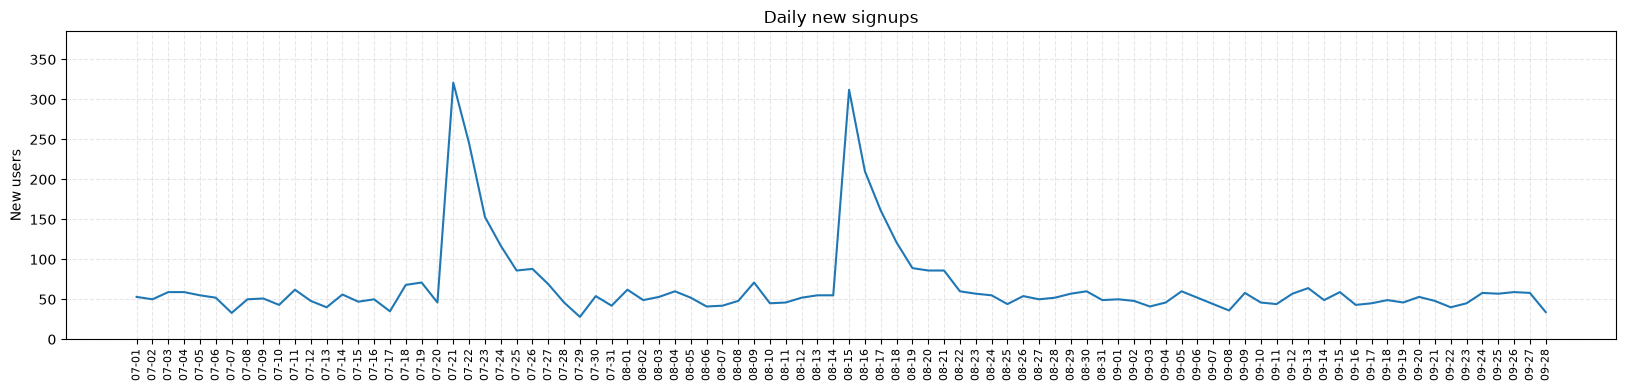

In [18]:
# 시각화
fig, ax = plt.subplots(figsize=(20, 4))

ax.plot(new_users_daily["signup_date"], new_users_daily["new_users"])
ax.set_ylim(0, new_users_daily["new_users"].max() * 1.2)     # y축을 0부터 시작
ax.set_title("Daily new signups")
ax.set_ylabel("New users")
ax.grid(alpha=0.3, linestyle="--")

ax.set_xticks(new_users_daily["signup_date"])
ax.set_xticklabels(new_users_daily["signup_date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

### **요점**
- **여름 축제 1부 기간 일부 (7/21~7/26), 2부 기간(8/15~8/21)**: 신규 유저의 유입이 두드러졌고, 특히 첫날에 신규 가입이 급등함.  
    - 이는 축제 콘텐츠의 영향일 수도, 프로모션 기간 진행한 마케팅의 영향일 수도 있음.
    - **한계점**: 마케팅을 진행하지 않은 유사한 프로모션 데이터가 없어 어느 쪽의 영향이 큰지 구분할 수 없음. 추후 확인 필요.

### 5-2. 가입일별 핵심 마일스톤 리텐션

In [19]:
# 핵심 마일스톤 도출하기

# 신규 유저 유입 후 DN일별 접속자 비율 확인하기

# 가입 후 경과일(day_n) 계산
# day_n = 접속일 - 가입일 (가입한 날 = D0)
act_users = daily[["user_id", "date"]].merge(new_users, on="user_id")
act_users["day_n"] = (act_users["date"] - act_users["signup_date"]).dt.days

# 최대 30일까지 확인
max_day = 30

rows = []
for n in range(0, max_day + 1):
    # 유입 후 N일째에 접속한 유저 수
    active_cnt = act_users[act_users["day_n"] == n]["user_id"].nunique()

    rows.append({
        "day_n": n,
        "active_users": active_cnt,
        "revisit(%)": round(active_cnt / new_users_cnt * 100, 2)
    })

curve = pd.DataFrame(rows).set_index("day_n")
curve["change(%p)"] = curve["revisit(%)"].diff().round(2)

display(curve)

,active_users,revisit(%),change(%p)
day_n,,,
0,6000,100.00,NaN
1,2316,38.60,-61.40
2,1785,29.75,-8.85
3,1491,24.85,-4.90
4,1279,21.32,-3.53
5,1131,18.85,-2.47
6,998,16.63,-2.22
7,917,15.28,-1.35
8,846,14.10,-1.18


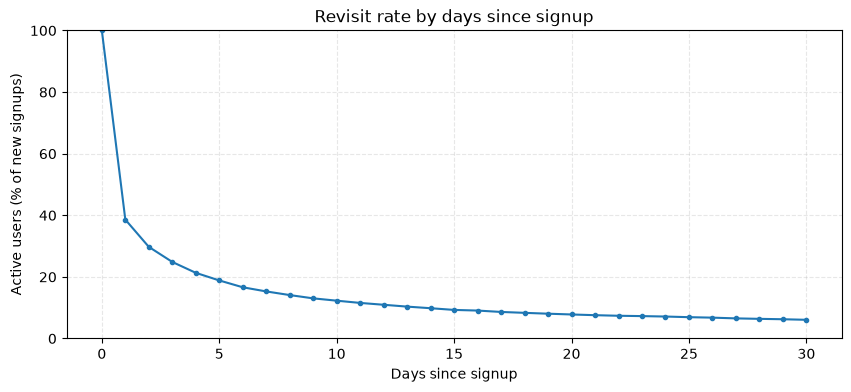

In [20]:
# 시각화
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(curve.index, curve["revisit(%)"], marker="o", markersize=3)
ax.set_ylim(0, 100)
ax.set_title("Revisit rate by days since signup")
ax.set_xlabel("Days since signup")
ax.set_ylabel("Active users (% of new signups)")
ax.grid(alpha=0.3, linestyle="--")

plt.show()

**핵심 마일스톤**  

일반적으로 `D1`, `D3`, `D7`, `D14`, `D21`, `D30`을 마일스톤으로 보는데, 리텐션 감소폭이 완만해지는 시기는 **`D14`** 즈음임.  
D1에서 D14까지는 리텐션이 **28.8%p** 감소했고, D14에서 D30까지는 **3.8%p**만 감소함.  
따라서 **D1, D3, D7, D14**를 핵심 마일스톤으로 정하고 분석함.

In [21]:
milestones = [1, 3, 7, 14]

# 신규 가입자의 접속 기록에 가입 후 경과일 붙이기
new_signups = users[users["signup_date"] >= obs_start]
act_new = daily[["user_id", "date"]].merge(new_signups[["user_id", "signup_date"]], on="user_id")
act_new["day_n"] = (act_new["date"] - act_new["signup_date"]).dt.days

signup_size = new_signups.groupby("signup_date")["user_id"].nunique()    # 가입일별 가입자 수

# 가입일별 Dn 리텐션(%)
daily_retention = pd.DataFrame(index=signup_size.index)

for n in milestones:
    returned = act_new[act_new["day_n"] == n].groupby("signup_date")["user_id"].nunique()
    daily_retention[f"D{n}"] = (returned / signup_size * 100).fillna(0).round(2)
    not_mature = signup_size.index + pd.Timedelta(days=n) > obs_end     # 가입 후 n일이 아직 안 지난 가입일
    daily_retention.loc[not_mature, f"D{n}"] = np.nan

daily_retention.insert(0, "signups", signup_size)    # 맨 앞에 가입자 수 컬럼 추가
daily_retention.index.name = "signup_date"

daily_retention

,signups,D1,D3,D7,D14
signup_date,,,,,
2026-07-01,53,37.74,26.42,15.09,11.32
2026-07-02,50,36.00,26.00,16.00,12.00
2026-07-03,59,47.46,25.42,18.64,13.56
2026-07-04,59,44.07,25.42,20.34,15.25
2026-07-05,55,30.91,18.18,14.55,9.09
...,...,...,...,...,...
2026-09-24,58,34.48,20.69,NaN,NaN
2026-09-25,57,40.35,21.05,NaN,NaN
2026-09-26,59,37.29,NaN,NaN,NaN


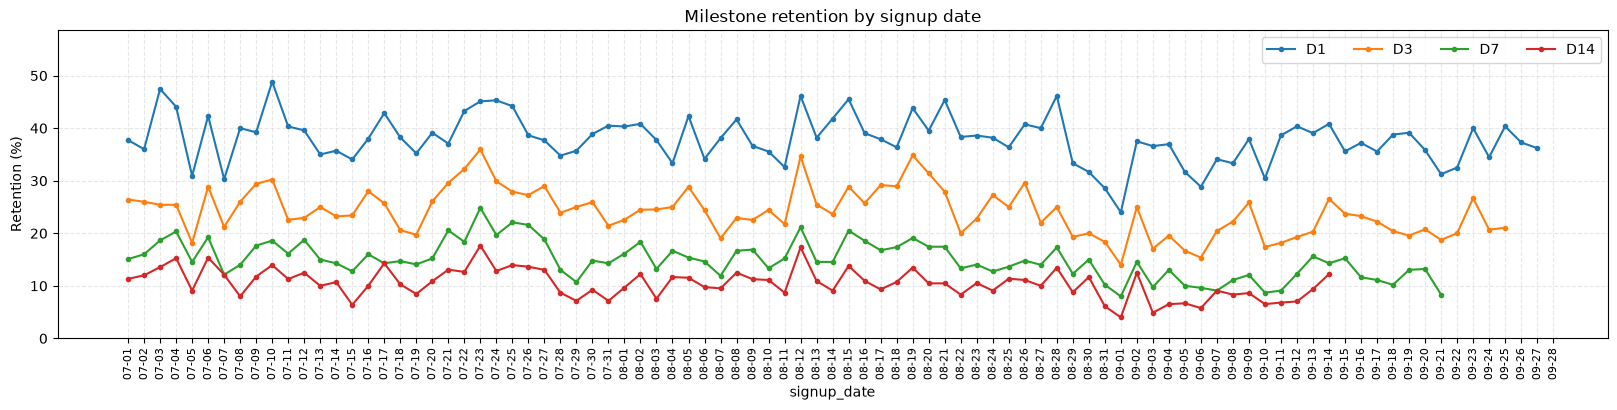

In [22]:
# 시각화
fig, ax = plt.subplots(figsize=(20, 4))

for n in milestones:
    ax.plot(daily_retention.index, daily_retention[f"D{n}"], marker="o", markersize=3, label=f"D{n}")

ax.set_ylim(0, daily_retention[[f"D{n}" for n in milestones]].max().max() * 1.2)     # y축을 0부터 시작
ax.set_title("Milestone retention by signup date")
ax.set_xlabel("signup_date")
ax.set_ylabel("Retention (%)")
ax.legend(loc="upper right", ncol=len(milestones))   # 범례를 위쪽 한 줄로
ax.grid(alpha=0.3, linestyle="--")

ax.set_xticks(daily_retention.index)
ax.set_xticklabels(daily_retention.index.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

### **요점**
- **8/29~9/1 기간 가입자**: D1~D14 리텐션이 모두 큰 폭으로 감소함.
    - 이 시기에 확인된 프로모션이나 이슈는 확인할 수 없었기에 다른 원인이 있었을 수 있음.
    - 8/30 성장 개편 업데이트와 시점이 겹쳐 업데이트의 영향일 가능성도 있으나, 8/29 부터 감소에 대한 구체적인 원인은 주어진 데이터 및 정보로는 파악이 어려움.  추후 확인 필요.
- **8/29 이후 가입 코호트**: 전반적으로 이전보다 리텐션이 낮게 나타남.
    - 신규 유저의 반복 활동을 이끌 유인이 필요해 보임.

### 5-3. 가입 주별 리텐션

In [23]:
days = [1, 3, 7, 14, 30]

# 신규 가입자의 가입 주(월요일 날짜)
new_users["cohort_week"] = new_users["signup_date"] - pd.to_timedelta(new_users["signup_date"].dt.weekday, unit="D")
cohort_size = new_users.groupby("cohort_week")["user_id"].nunique()

act = daily[["user_id", "date"]].merge(new_users[["user_id", "signup_date", "cohort_week"]], on="user_id")
act["day_n"] = (act["date"] - act["signup_date"]).dt.days

# 주별 Dn 리텐션(%)
retention = pd.DataFrame(index=cohort_size.index)
for n in days:
    returned = act[act["day_n"] == n].groupby("cohort_week")["user_id"].nunique()
    retention[f"D{n}"] = (returned / cohort_size * 100).fillna(0).round(2)
    not_mature = cohort_size.index + pd.Timedelta(days=6 + n) > obs_end   # 주의 마지막 가입자가 n일을 못 채운 코호트
    retention.loc[not_mature, f"D{n}"] = np.nan
retention.insert(0, "cohort_size", cohort_size)    # 맨 앞에 가입자 수 컬럼 추가
retention.index = retention.index.strftime("%Y-%m-%d")
retention.index.name = "cohort_week"

retention

,cohort_size,D1,D3,D7,D14,D30
cohort_week,,,,,,
2026-06-29,276,39.49,24.28,17.03,12.32,8.70
2026-07-06,339,40.41,25.96,16.81,12.09,8.26
2026-07-13,367,36.78,23.16,14.44,9.81,6.54
2026-07-20,1056,41.38,30.68,20.55,13.64,9.85
2026-07-27,350,38.57,24.86,15.71,10.00,5.71
2026-08-03,367,37.60,23.98,15.26,10.63,6.27
2026-08-10,775,41.68,27.10,18.45,12.26,8.26
2026-08-17,660,39.70,28.64,16.82,10.45,7.88
2026-08-24,372,37.90,23.92,14.25,10.75,NaN


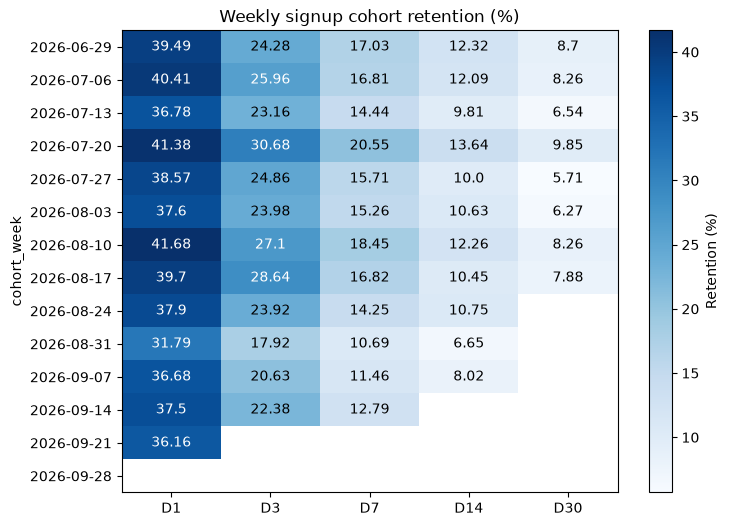

In [24]:
# 시각화
data = retention.drop(columns="cohort_size")          # 가입자 수 컬럼은 색칠에서 제외

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(data.values, cmap="Blues", aspect="auto")      # 우측 색상막대: 값이 클수록 진한 파랑, NaN은 빈칸

ax.set_xticks(range(len(data.columns)), data.columns)         # 가로 눈금: D1, D3, ...
ax.set_yticks(range(len(data.index)), data.index)             # 세로 눈금: 가입 주

for i in range(data.shape[0]):                                # 칸마다 숫자 쓰기
    for j in range(data.shape[1]):
        value = data.iloc[i, j]
        if not np.isnan(value):
            color = "white" if value > data.max().max() * 0.6 else "black"
            ax.text(j, i, f"{value}", ha="center", va="center", color=color)

fig.colorbar(im, label="Retention (%)")
ax.set_title("Weekly signup cohort retention (%)")
ax.set_ylabel("cohort_week")

plt.show()

In [25]:
# 프로모션 아닌 기간 vs 프로모션 기간별 일평균 신규 가입자 수, 가입일 기준 D1/D7/D14/D30 리텐션

# 가입일별 신규 가입자 수
signup_size = new_users_daily.set_index("signup_date")["new_users"]

# 신규 가입자의 접속 기록에 가입 후 경과일 붙이기
new_signups = users[users["signup_date"] >= obs_start]
act_new = daily[["user_id", "date"]].merge(new_signups[["user_id", "signup_date"]], on="user_id")
act_new["day_n"] = (act_new["date"] - act_new["signup_date"]).dt.days

# 가입일별 Dn 리텐션(%) (가입 후 n일이 아직 안 지난 가입일은 NaN)
ret_days = [1, 7, 14, 30]
ret_cols = [f"D{n}" for n in ret_days]

signup_s = pd.DataFrame({"signups": signup_size})
for n in ret_days:
    returned = act_new[act_new["day_n"] == n].groupby("signup_date")["user_id"].nunique()
    signup_s[f"D{n}"] = (returned / signup_size * 100).fillna(0)
    not_mature = signup_s.index + pd.Timedelta(days=n) > obs_end
    signup_s.loc[not_mature, f"D{n}"] = np.nan

# 프로모션 및 업데이트 기간에 해당하는 가입일 표시 (평시: 그 외 기간, 핫픽스일 제외)
event_mask_r = pd.Series(False, index=signup_s.index)
for start, end in periods.values():
    event_mask_r = event_mask_r | ((signup_s.index >= pd.Timestamp(start)) & (signup_s.index <= pd.Timestamp(end)))
non_promo_mask_r = ~event_mask_r & (signup_s.index != hotfix_date)

# 구분별 마스크 (평시 + 프로모션 기간)
masks = {"프로모션 아닌 기간": ("그 외 기간", non_promo_mask_r)}
for name, (start, end) in periods.items():
    in_period = (signup_s.index >= pd.Timestamp(start)) & (signup_s.index <= pd.Timestamp(end))
    masks[name] = (f"{start[5:]} ~ {end[5:]}", in_period)

# 기간별 일평균 신규 가입자 수와 평균 리텐션
rows = []
for name, (period_label, mask) in masks.items():
    row = {"구분": name, "기간": period_label}
    row["일평균 신규 가입자"] = signup_s.loc[mask, "signups"].mean()
    for col in ret_cols:
        row[f"{col} 리텐션(%)"] = signup_s.loc[mask, col].mean()
    rows.append(row)

signup_by_period = pd.DataFrame(rows).set_index("구분")

# 프로모션 아닌 기간(평시) 대비 차이
base_signup = signup_by_period.loc["프로모션 아닌 기간", "일평균 신규 가입자"]
signup_by_period["신규 가입자 평시 대비(%)"] = ((signup_by_period["일평균 신규 가입자"] / base_signup - 1) * 100).round(1)

for col in ret_cols:
    base_ret = signup_by_period.loc["프로모션 아닌 기간", f"{col} 리텐션(%)"]
    signup_by_period[f"{col} 평시 대비(%p)"] = (signup_by_period[f"{col} 리텐션(%)"] - base_ret).round(2)

# 표시할 때만 소수점과 부호 적용 (값은 숫자 그대로)
fmt = {"일평균 신규 가입자": "{:,.0f}", "신규 가입자 평시 대비(%)": "{:+.1f}%"}
for col in ret_cols:
    fmt[f"{col} 리텐션(%)"] = "{:.2f}"
    fmt[f"{col} 평시 대비(%p)"] = "{:+.2f}%p"

display(signup_by_period.style.format(fmt))

,기간,일평균 신규 가입자,D1 리텐션(%),D7 리텐션(%),D14 리텐션(%),D30 리텐션(%),신규 가입자 평시 대비(%),D1 평시 대비(%p),D7 평시 대비(%p),D14 평시 대비(%p),D30 평시 대비(%p)
구분,,,,,,,,,,,
프로모션 아닌 기간,그 외 기간,51,38.61,15.24,10.76,7.28,+0.0%,+0.00%p,+0.00%p,+0.00%p,+0.00%p
여름 축제 1부,07-21 ~ 07-27,154,41.61,20.85,13.83,9.59,+200.7%,+3.00%p,+5.61%p,+3.07%p,+2.31%p
여름 축제 2부,08-15 ~ 08-21,152,41.07,18.17,11.32,8.37,+196.8%,+2.47%p,+2.93%p,+0.56%p,+1.09%p
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,50,32.21,11.03,7.47,nan,-2.5%,-6.40%p,-4.21%p,-3.29%p,+nan%p
핫픽스일,09-08 ~ 09-08,36,33.33,11.11,8.33,nan,-29.8%,-5.27%p,-4.13%p,-2.43%p,+nan%p
복귀 지원 이벤트,09-09 ~ 09-15,54,37.55,12.47,8.43,nan,+5.1%,-1.06%p,-2.77%p,-2.33%p,+nan%p
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,49,36.55,11.25,nan,nan,-4.7%,-2.06%p,-3.99%p,+nan%p,+nan%p


### **요점**
- **여름 축제 1부 가입 코호트(7/21~7/27)**: 다른 주 대비 D1, D7, D14, D30 모두에서 높은 리텐션을 형성.  
    - 이후 여름 축제 2부로 이어지면서 신규 유저가 지속적으로 이용했을 가능성이 있음.
- **여름 축제 2부 가입 코호트(8/15~8/21)**: 여름 축제 1부보다는 낮지만, 평시 대비 소폭 높은 리텐션을 형성.
    - 1부에 이미 몰입도 높은 유저가 유입되었거나, 한정 코스튬이 희소성을 잃어 신규 유저의 몰입 요인이 줄었을 가능성이 있음.
- **D30 리텐션**: 여름 축제 1, 2부 가입 유저는 D30 리텐션도 평시 가입 유저보다 약 1~2%p 높게 나타남.
    - 광고로 유입되었거나 축제 콘텐츠를 경험한 유저의 정착률이 높았을 가능성이 있음.
- **성장 개편 업데이트 이후 핫픽스 전 가입 코호트(8/30~9/7)**: D1 -6.40%p, D7 -4.21%p로 평시보다 D1, D7 리텐션이 가장 낮음.

## 6. 성장 퍼널과 병목 구간

In [26]:
# 신규 가입 유저의 Lv30 달성까지 걸린 일수와 플레이타임

# 관측 기간 안에 가입한 유저 추출
new_users = users[users["signup_date"] >= obs_start][["user_id", "signup_date"]]

# 유저별 Lv30 달성일 추출
lv30 = events[events["event"] == "reach_lv30"][["user_id", "event_time"]].copy()
lv30["lv30_date"] = lv30["event_time"].dt.normalize()

# 가입 + Lv30 달성 유저만 남기기
reached = new_users.merge(lv30[["user_id", "lv30_date"]], on="user_id")

# 가입일부터 Lv30까지 달성일수 추가
reached["days_to_lv30"] = (reached["lv30_date"] - reached["signup_date"]).dt.days + 1

# 가입일부터 Lv30 달성일까지 총 플레이타임
# 한계: Lv30을 달성한 날의 총 플레이타임이 들어가므로, 명확하게는 Lv30 달성 이후의 플레이타임도 포함될 수 있음
act = daily[["user_id", "date", "playtime_min"]].merge(reached[["user_id", "lv30_date"]], on="user_id")
act = act[act["date"] <= act["lv30_date"]]

playtime_sum = act.groupby("user_id")["playtime_min"].sum()
reached["playtime_to_lv30_hrs"] = reached["user_id"].map(playtime_sum) / 60

# 요약: 평균, 중앙값, Q1, Q3, 최댓값, 상한(Q3 + 1.5 * IQR)
cols = ["days_to_lv30", "playtime_to_lv30_hrs"]

summary = pd.DataFrame({
    "mean": reached[cols].mean(),
    "median": reached[cols].median(),
    "Q1": reached[cols].quantile(0.25),
    "Q3": reached[cols].quantile(0.75),
    "max": reached[cols].max(),
}).round(2)

reached_lv30_cnt = len(reached)

print(f"Lv30 달성 유저: {reached_lv30_cnt:,}명 (신규 가입 {new_users_cnt:,}명 중, {reached_lv30_cnt / new_users_cnt * 100:.1f}%)")
print("\n[Lv30까지 걸린 일수와 플레이타임 요약]")
display(summary)

# N일 이내 누적 달성 (분모: Lv30 달성자 전체)
days = reached["days_to_lv30"]

rows = []
for n in [7, 14, 21, 30, 40, 50, 60]:
    cnt = (days <= n).sum()
    rows.append({
        "가입 후 N일 이내": n,
        "누적 달성 유저": cnt,
        "달성자 중(%)": round(cnt / reached_lv30_cnt * 100, 2),
        "신규 가입자 중(%)": round(cnt / new_users_cnt * 100, 2)
    })

cumulative = pd.DataFrame(rows)

print("\n[N일 이내 누적 달성]")
display(cumulative)

Lv30 달성 유저: 1,220명 (신규 가입 6,000명 중, 20.3%)

[Lv30까지 걸린 일수와 플레이타임 요약]


,mean,median,Q1,Q3,max
days_to_lv30,15.14,11.00,7.00,20.00,82.00
playtime_to_lv30_hrs,25.35,16.16,14.07,19.74,163.80



[N일 이내 누적 달성]


,가입 후 N일 이내,누적 달성 유저,달성자 중(%),신규 가입자 중(%)
0,7,373,30.57,6.22
1,14,756,61.97,12.60
2,21,959,78.61,15.98
3,30,1085,88.93,18.08
4,40,1168,95.74,19.47
5,50,1202,98.52,20.03
6,60,1213,99.43,20.22


In [27]:
# 최소 관측일별 퍼널 분석 대상 유저 수 비교

# 비교할 최소 관측일
min_days_list = [30, 40, 50, 60]

# 데이터 기간 내 신규 가입자
new_signups = users[users["signup_date"] >= obs_start]
total_cnt = len(new_signups)

rows = []
for min_days in min_days_list:
    # 데이터 종료일 기준 min_days일 이전까지 가입한 유저만 대상
    cohort_end = obs_end - pd.Timedelta(days=min_days)
    cohort = new_signups[new_signups["signup_date"] <= cohort_end]
    cohort_cnt = len(cohort)

    rows.append({
        "최소 관측일": min_days,
        "가입 종료일": cohort_end.date(),
        "대상 유저 수": cohort_cnt,
        "신규 가입자 중(%)": round(cohort_cnt / total_cnt * 100, 1)
    })

cohort_compare = pd.DataFrame(rows).set_index("최소 관측일")
display(cohort_compare.style.format({"대상 유저 수": "{:,}", "신규 가입자 중(%)": "{:.2f}%"}))

,가입 종료일,대상 유저 수,신규 가입자 중(%)
최소 관측일,,,
30,2026-08-29,"4,502",75.00%
40,2026-08-19,"3,901",65.00%
50,2026-08-09,"2,755",45.90%
60,2026-07-30,"2,235",37.20%


**퍼널 분석 대상 유저 범위**
- **가입 후 40일 이상 지난 신규 가입 코호트**를 대상으로 분석함.
    - 이유 1: 가입일을 제한하지 않으면 가입 후 충분한 시간이 지나지 않은 유저까지 포함되어 분석 결과가 왜곡됨.
    - 이유 2: **Lv30 달성자의 95.74%가 가입 후 40일 이내에 달성**함. 40일 이후에는 달성률 증가폭이 작아짐(50일 98.52%, 60일 99.43%).
    - 이유 3: 최소 관측일이 길수록 대상 유저 수가 줄어듦. 예를 들어, 60일로 하면 대상 유저가 **2,235명**(신규 가입자의 37.2%)으로 줄지만, 40일은 **3,901명**(65.0%)임.

In [28]:
# 데이터 마지막 날 기준 가입 후 40일 이상 지난 신규 가입 코호트

# 데이터 종료일 40일 전
cohort_end = obs_end - pd.Timedelta(days=40)

cohort = users[users["signup_date"].between(obs_start, cohort_end)]
print(f"데이터 시작일: {obs_start.date()}")
print(f"데이터 종료일: {obs_end.date()}")
print(f"데이터 종료일 40일 전: {cohort_end.date()}")
print(f"가입 후 40일 이상 지난 신규 가입 유저 수: {len(cohort):,}명 (신규 가입 {new_users_cnt:,}명 중, {len(cohort) / new_users_cnt * 100:.1f}%)")

데이터 시작일: 2026-07-01
데이터 종료일: 2026-09-28
데이터 종료일 40일 전: 2026-08-19
가입 후 40일 이상 지난 신규 가입 유저 수: 3,901명 (신규 가입 6,000명 중, 65.0%)


In [29]:
# 신규 가입 코호트 대상 성장 이벤트 퍼널
steps = ["tutorial_complete", "reach_lv10", "first_dungeon", "reach_lv30"]

step_users = (events[events["user_id"].isin(cohort["user_id"]) & events["event"].isin(steps)]
              .groupby("event")["user_id"].nunique()
              .reindex(steps))

funnel = pd.DataFrame({"step": ["signup"] + steps,
                       "users": [len(cohort)] + step_users.tolist()})
funnel["pct_of_signup"] = (funnel["users"] / funnel["users"].iloc[0] * 100).round(1)
funnel["pct_of_prev"] = (funnel["users"] / funnel["users"].shift(1) * 100).round(1)
funnel["drop_from_prev"] = funnel["users"].shift(1) - funnel["users"]
funnel

,step,users,pct_of_signup,pct_of_prev,drop_from_prev
0,signup,3901,100.00,NaN,NaN
1,tutorial_complete,3623,92.90,92.90,278.00
2,reach_lv10,3203,82.10,88.40,420.00
3,first_dungeon,1399,35.90,43.70,"1,804.00"
4,reach_lv30,971,24.90,69.40,428.00


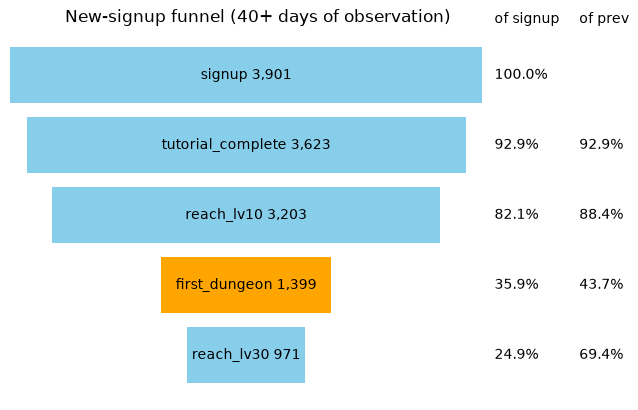

In [30]:
# 시각화
x1 = funnel["users"].max() / 2 + 100     # pct_of_signup 열의 가로 위치
x2 = x1 + 700                            # pct_of_prev 열의 가로 위치

plt.text(x1, 0.8, "of signup", va="center")   # 열 제목
plt.text(x2, 0.8, "of prev", va="center")

for i, row in funnel.iterrows():
    color = "orange" if row["step"] == "first_dungeon" else "skyblue"

    plt.barh(-i, row["users"], left=-row["users"] / 2, color=color)
    plt.text(0, -i, f'{row["step"]} {row["users"]:,}', ha="center", va="center")
    plt.text(x1, -i, f'{row["pct_of_signup"]}%', va="center")
    if i > 0:
        plt.text(x2, -i, f'{row["pct_of_prev"]}%', va="center")

plt.title("New-signup funnel (40+ days of observation)")
plt.axis("off")

plt.show()

### **요점**
- **병목 구간**: 가입 후 40일 이상 지난 신규 유저의 Lv30까지 전환율을 확인했을 때, **reach_lv10 → first_dungeon** 전환율이 **43.7%** 로 가장 낮아 병목 구간으로 확인됨.
    - 첫 던전의 난이도가 높거나 콘텐츠의 재미가 떨어지는 등의 원인을 추측해볼 수 있음.
    - **한계점**: 구체적으로 던전의 어느 지점에서 이탈했는지는 로그 등 추가 데이터 필요. 추가로 온라인 포럼, SNS 등의 리서치를 통한 추후 확인이 필요함.

## 7. 매출

### 7-1. 매출
- **매출**: `payments`의 `amount_krw` 합계 (원)

In [31]:
# 결제가 일어난 날짜
pay_date = payments["paid_at"].dt.normalize().rename("date")

# 일별 결제 유저 수, 매출
daily_pay = payments.groupby(pay_date).agg(payers=("user_id", "nunique"),
                                           revenue=("amount_krw", "sum")).reset_index()

# DAU 날짜에 맞춰 붙이기 (결제가 없는 날은 0)
revenue_daily = dau[["date"]].merge(daily_pay, on="date", how="left")
revenue_daily[["payers", "revenue"]] = revenue_daily[["payers", "revenue"]].fillna(0)

# 전체 기간 총매출, 일평균 매출
total_revenue = revenue_daily["revenue"].sum()
avg_daily_revenue = revenue_daily["revenue"].mean()
n_days = len(revenue_daily)

print(f"분석 기간: {n_days}일")
print(f"총매출: {total_revenue:,.0f}원")
print(f"일평균 매출: {avg_daily_revenue:,.0f}원")

revenue_daily.head()

분석 기간: 90일
총매출: 118,336,900원
일평균 매출: 1,314,854원


,date,payers,revenue
0,2026-07-01,17,672100
1,2026-07-02,23,838200
2,2026-07-03,27,1013100
3,2026-07-04,31,993300
4,2026-07-05,27,1024100


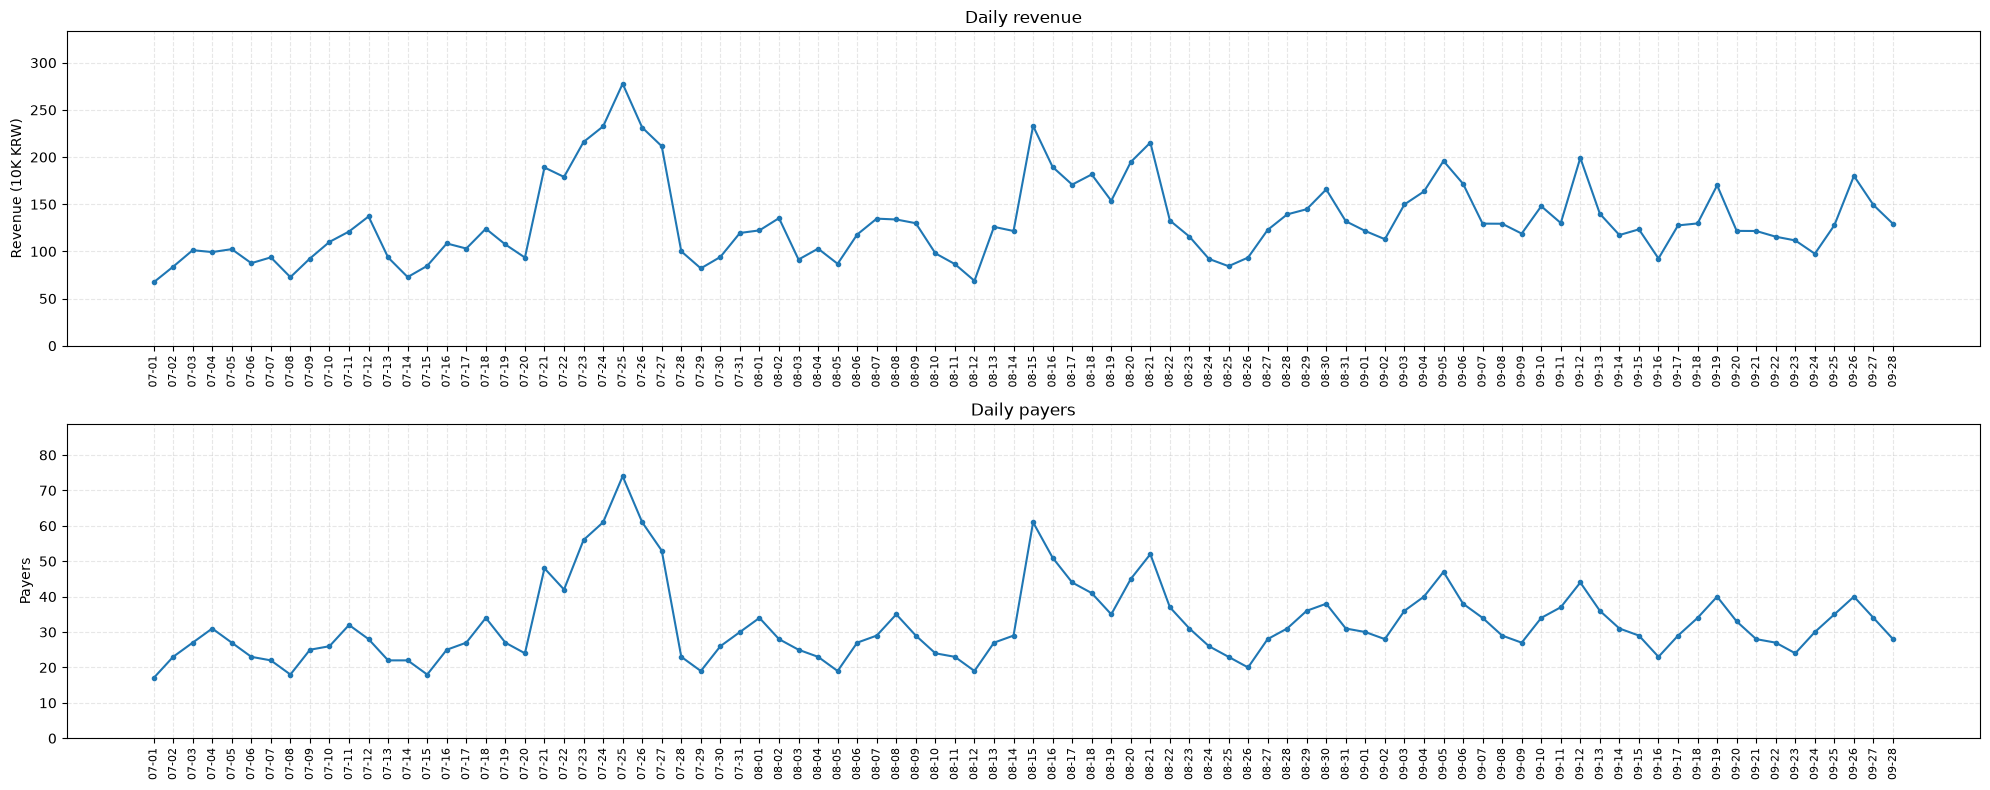

In [32]:
# 시각화: 위 일별 매출, 아래 일별 결제자 수

# 매출은 만 원 단위로 변환
revenue_10k = revenue_daily["revenue"] / 10000

# (y값, 제목, y축 이름)
charts = [
    (revenue_10k, "Daily revenue", "Revenue (10K KRW)"),
    (revenue_daily["payers"], "Daily payers", "Payers"),
]

fig, axes = plt.subplots(2, 1, figsize=(20, 8))

for ax, (values, title, ylabel) in zip(axes, charts):
    ax.plot(revenue_daily["date"], values, marker="o", markersize=3)
    ax.set_ylim(0, values.max() * 1.2)     # y축을 0부터 시작
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3, linestyle="--")

    # x축 눈금은 두 그래프 모두 표시
    ax.set_xticks(revenue_daily["date"])
    ax.set_xticklabels(revenue_daily["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

In [33]:
# 프로모션 아닌 기간 vs 프로모션 기간별 총매출, 일평균 매출, 매출 비중

# 일자별 매출 (날짜를 인덱스로)
revenue_s = revenue_daily.set_index("date")["revenue"]

# 구분별 마스크 (평시 + 프로모션 및 업데이트 기간 + 핫픽스일)
masks = {"프로모션 아닌 기간": ("그 외 기간", non_promo_mask)}
for name, (start, end) in periods.items():
    in_period = (revenue_s.index >= pd.Timestamp(start)) & (revenue_s.index <= pd.Timestamp(end))
    masks[name] = (f"{start[5:]} ~ {end[5:]}", in_period)

# 기간별 일수, 총매출, 일평균 매출
rows = []
for name, (period_label, mask) in masks.items():
    period_revenue = revenue_s[mask]
    rows.append({
        "구분": name,
        "기간": period_label,
        "일수": len(period_revenue),
        "총매출": period_revenue.sum(),
        "일평균 매출": period_revenue.mean()
    })

revenue_by_period = pd.DataFrame(rows).set_index("구분")

# 전체 매출 중 비중(%), 프로모션 아닌 기간(평시) 대비 일평균 매출 증감률(%)
base_revenue = revenue_by_period.loc["프로모션 아닌 기간", "일평균 매출"]
revenue_by_period["매출 비중(%)"] = (revenue_by_period["총매출"] / total_revenue * 100).round(1)
revenue_by_period["일평균 평시 대비(%)"] = ((revenue_by_period["일평균 매출"] / base_revenue - 1) * 100).round(1)

# 표시할 때만 쉼표와 부호 적용 (값은 숫자 그대로)
display(revenue_by_period.style.format({
    "총매출": "{:,.0f}",
    "일평균 매출": "{:,.0f}",
    "매출 비중(%)": "{:.1f}%",
    "일평균 평시 대비(%)": "{:+.1f}%"
}))

,기간,일수,총매출,일평균 매출,매출 비중(%),일평균 평시 대비(%)
구분,,,,,,
프로모션 아닌 기간,그 외 기간,46,"48,340,600","1,050,883",40.8%,+0.0%
여름 축제 1부,07-21 ~ 07-27,7,"15,371,400","2,195,914",13.0%,+109.0%
여름 축제 2부,08-15 ~ 08-21,7,"13,389,200","1,912,743",11.3%,+82.0%
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,9,"13,428,800","1,492,089",11.3%,+42.0%
핫픽스일,09-08 ~ 09-08,1,"1,293,600","1,293,600",1.1%,+23.1%
복귀 지원 이벤트,09-09 ~ 09-15,7,"9,769,100","1,395,586",8.3%,+32.8%
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,13,"16,744,200","1,288,015",14.1%,+22.6%


In [34]:
# 프로모션 아닌 기간 vs 프로모션 기간별 결제자 수

# 일자별 결제 유저 수 (날짜를 인덱스로)
payers_s = revenue_daily.set_index("date")["payers"]

# 기간별 결제자 수, 일평균 결제자 수 (masks는 위 매출 표에서 만든 것을 사용)
rows = []
for name, (period_label, mask) in masks.items():
    period_dates = payers_s.index[mask]

    # 기간 안에 한 번이라도 결제한 유저 수 (중복 제외)
    period_payers = payments.loc[pay_date.isin(period_dates), "user_id"].nunique()

    rows.append({
        "구분": name,
        "기간": period_label,
        "일수": len(period_dates),
        "결제자 수": period_payers,
        "일평균 결제자 수": payers_s[mask].mean()
    })

payers_by_period = pd.DataFrame(rows).set_index("구분")

# 프로모션 아닌 기간(평시) 대비 일평균 결제자 수 증감률(%)
base_payers = payers_by_period.loc["프로모션 아닌 기간", "일평균 결제자 수"]
payers_by_period["일평균 평시 대비(%)"] = ((payers_by_period["일평균 결제자 수"] / base_payers - 1) * 100).round(1)

# 표시할 때만 쉼표와 부호 적용 (값은 숫자 그대로)
display(payers_by_period.style.format({
    "결제자 수": "{:,}",
    "일평균 결제자 수": "{:,.1f}",
    "일평균 평시 대비(%)": "{:+.1f}%"
}))

,기간,일수,결제자 수,일평균 결제자 수,일평균 평시 대비(%)
구분,,,,,
프로모션 아닌 기간,그 외 기간,46,833,26.1,+0.0%
여름 축제 1부,07-21 ~ 07-27,7,353,56.4,+116.5%
여름 축제 2부,08-15 ~ 08-21,7,298,47.0,+80.3%
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,9,290,35.8,+37.3%
핫픽스일,09-08 ~ 09-08,1,29,29.0,+11.3%
복귀 지원 이벤트,09-09 ~ 09-15,7,223,34.0,+30.4%
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,13,354,31.2,+19.5%


### **요점**
- **전체 매출**: 90일간 총매출은 약 1억 1,834만 원, 일평균 매출은 약 131만 원.
- **여름 축제 1부, 2부**: 일평균 매출이 평시 대비 **+109.0%, +82.0%** 로 약 2배 수준.
    - 두 기간을 합치면 14일(분석 기간의 15.6%) 동안 전체 매출의 **24.3%** 가 발생함.
    - 일평균 결제자 수도 평시 대비 +116.5%, +80.3%로, 매출 증가율과 거의 같음. **매출 증가는 결제자 수 증가**에서 나온 것으로 보임.
    - **한계점**: 결제 금액(상품 가격)은 있지만 상품 정보가 없어, 여름 축제 1, 2부에서 판매했던 한정 코스튬의 매출 기여는 확인이 어려움.
- **성장 개편 업데이트 이후 핫픽스 전(8/30~9/7)**: DAU는 평시보다 낮았지만(-3.4%), 일평균 매출은 평시 대비 **+42.0%** 높았음.
- **복귀 지원 이벤트와 종료 후**: 평시보다 높은 매출이 이어짐. 8/30 이후로는 매출이 평시 수준 이상을 유지함.
- 매출 증가가 접속 유저 증가 때문인지, 1명당 결제 증가 때문인지는 7-2(ARPU, ARPPU)와 7-3(결제 전환율)에서 나눠서 확인함.

### 7-2. ARPU, ARPPU
- **ARPU**: 일 매출 ÷ DAU (접속 유저 1명당 매출)
- **ARPPU**: 일 매출 ÷ 일 결제 유저 수 (결제 유저 1명당 매출)

In [35]:
# 결제가 일어난 날짜
pay_date = payments["paid_at"].dt.normalize().rename("date")

# 일별 결제 유저 수, 매출
daily_pay = payments.groupby(pay_date).agg(payers=("user_id", "nunique"),
                                           revenue=("amount_krw", "sum")).reset_index()

# DAU 표에 붙여서 ARPU, ARPPU 계산
arpu_daily = dau.merge(daily_pay, on="date", how="left")
arpu_daily[["payers", "revenue"]] = arpu_daily[["payers", "revenue"]].fillna(0)    # 결제가 없는 날은 0
arpu_daily["arpu"] = (arpu_daily["revenue"] / arpu_daily["dau"]).round(0)          # 접속 유저 1명당 매출
arpu_daily["arppu"] = (arpu_daily["revenue"] / arpu_daily["payers"]).round(0)      # 결제 유저 1명당 매출
arpu_daily

,date,dau,payers,revenue,arpu,arppu
0,2026-07-01,2410,17,672100,279.00,"39,535.00"
1,2026-07-02,2619,23,838200,320.00,"36,443.00"
2,2026-07-03,2516,27,1013100,403.00,"37,522.00"
3,2026-07-04,2862,31,993300,347.00,"32,042.00"
4,2026-07-05,2818,27,1024100,363.00,"37,930.00"
...,...,...,...,...,...,...
85,2026-09-24,3029,30,975700,322.00,"32,523.00"
86,2026-09-25,2955,35,1278200,433.00,"36,520.00"
87,2026-09-26,3215,40,1800700,560.00,"45,018.00"
88,2026-09-27,3189,34,1491600,468.00,"43,871.00"


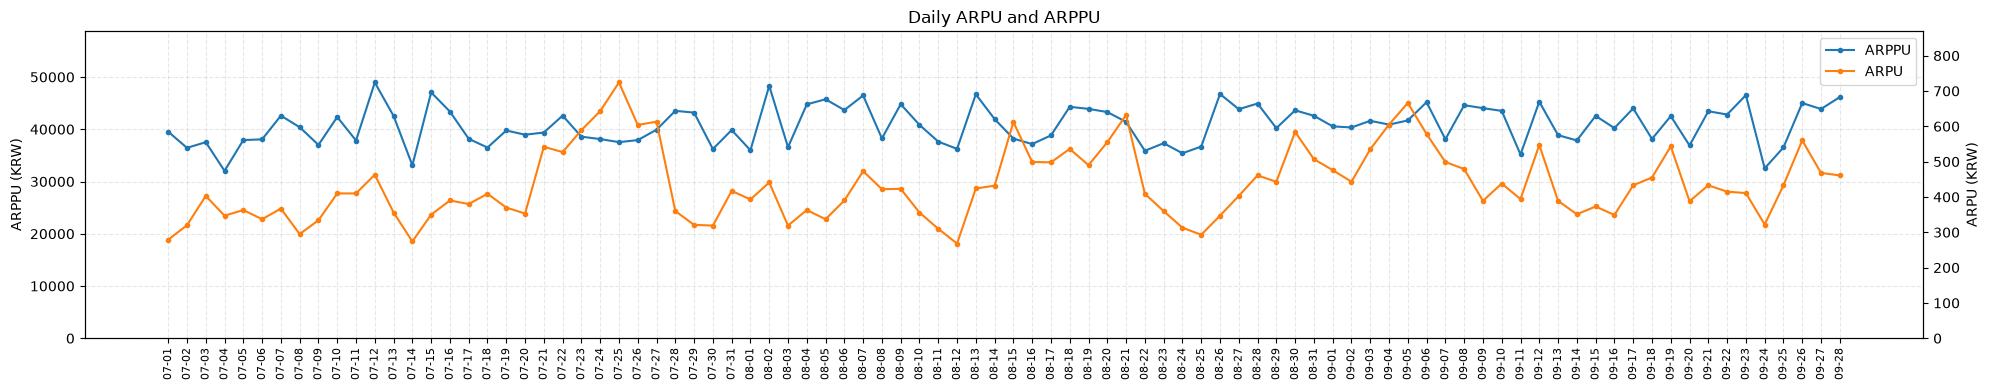

In [36]:
# 시각화
fig, ax1 = plt.subplots(figsize=(20, 4))
ax2 = ax1.twinx()

line1 = ax1.plot(arpu_daily["date"], arpu_daily["arppu"], marker="o", markersize=3, color="C0", label="ARPPU")
line2 = ax2.plot(arpu_daily["date"], arpu_daily["arpu"], marker="o", markersize=3, color="C1", label="ARPU")

ax1.set_ylim(0, arpu_daily["arppu"].max() * 1.2)     # y축을 0부터 시작
ax2.set_ylim(0, arpu_daily["arpu"].max() * 1.2)

ax1.set_ylabel("ARPPU (KRW)")
ax2.set_ylabel("ARPU (KRW)")
ax1.set_title("Daily ARPU and ARPPU")
ax1.grid(alpha=0.3, linestyle="--")

ax1.set_xticks(arpu_daily["date"])
ax1.set_xticklabels(arpu_daily["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

lines = line1 + line2                                # 두 축의 범례를 하나로 합침
ax1.legend(lines, [l.get_label() for l in lines])

plt.tight_layout()
plt.show()

In [37]:
# 프로모션 아닌 기간 vs 프로모션 기간별 일평균 ARPU, ARPPU

# 일자별 ARPU, ARPPU (날짜를 인덱스로)
arpu_s = arpu_daily.set_index("date")

rows = []

# 프로모션 아닌 기간
rows.append({
    "구분": "프로모션 아닌 기간",
    "기간": "그 외 기간",
    "일평균 ARPU": arpu_s.loc[non_promo_mask, "arpu"].mean(),
    "일평균 ARPPU": arpu_s.loc[non_promo_mask, "arppu"].mean()
})

# 프로모션 및 업데이트 기간별
for name, (start, end) in periods.items():
    in_period = (arpu_s.index >= pd.Timestamp(start)) & (arpu_s.index <= pd.Timestamp(end))

    rows.append({
        "구분": name,
        "기간": f"{start[5:]} ~ {end[5:]}",
        "일평균 ARPU": arpu_s.loc[in_period, "arpu"].mean(),
        "일평균 ARPPU": arpu_s.loc[in_period, "arppu"].mean()
    })

arpu_by_period = pd.DataFrame(rows).set_index("구분")

# 프로모션 아닌 기간(평시) 대비 증감률(%)
base_arpu = arpu_by_period.loc["프로모션 아닌 기간", "일평균 ARPU"]
base_arppu = arpu_by_period.loc["프로모션 아닌 기간", "일평균 ARPPU"]

arpu_by_period["ARPU 평시 대비(%)"] = ((arpu_by_period["일평균 ARPU"] / base_arpu - 1) * 100).round(1)
arpu_by_period["ARPPU 평시 대비(%)"] = ((arpu_by_period["일평균 ARPPU"] / base_arppu - 1) * 100).round(1)

# 표시할 때만 쉼표와 부호 적용 (값은 숫자 그대로)
display(arpu_by_period.style.format({
    "일평균 ARPU": "{:,.0f}",
    "일평균 ARPPU": "{:,.0f}",
    "ARPU 평시 대비(%)": "{:+.1f}%",
    "ARPPU 평시 대비(%)": "{:+.1f}%"
}))

,기간,일평균 ARPU,일평균 ARPPU,ARPU 평시 대비(%),ARPPU 평시 대비(%)
구분,,,,,
프로모션 아닌 기간,그 외 기간,370,"40,476",+0.0%,+0.0%
여름 축제 1부,07-21 ~ 07-27,606,"39,150",+63.9%,-3.3%
여름 축제 2부,08-15 ~ 08-21,546,"41,016",+47.7%,+1.3%
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,544,"41,618",+47.0%,+2.8%
핫픽스일,09-08 ~ 09-08,479,"44,607",+29.6%,+10.2%
복귀 지원 이벤트,09-09 ~ 09-15,412,"41,041",+11.3%,+1.4%
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,436,"41,436",+18.0%,+2.4%


### **요점**
- **여름 축제 1부(7/21~7/27)**: 일평균 ARPU가 평시 대비 **+63.9%** 상승함.
    - ARPPU는 평시 대비 **-3.3%** 로 소폭 낮았음.  
      결제 유저 1명당 결제금액은 비슷한데 ARPU가 크게 올라, 결제 금액이 커졌다기보다 결제하는 유저가 늘어난 영향으로 보임.
- **여름 축제 2부(8/15~8/21)**: ARPU가 평시 대비 **+47.7%** 상승했고, ARPPU는 +1.3%로 약간의 상승이 있었음.
- **성장 개편 업데이트 이후 핫픽스 전(8/30~9/7)**: DAU는 평시보다 낮았지만(-3.4%), ARPU는 평시 대비 **+47.0%** 로 여름 축제 2부 수준까지 상승함.  
    - 필드 사냥 경험치 하향을 결제로 보완하려는 유저가 늘었을 가능성이 있음.
- **전반적인 경향**: ARPPU는 프로모션 여부와 관계없이 큰 변동이 없었고, 여름 축제 프로모션에서 ARPU가 크게 상승함.
    - 비과금 유저나 소과금 유저의 결제를 끌어내는 데 효과적이었던 것으로 보임.

### 7-3. 결제 전환율

In [38]:
# 일별 결제 전환율 (결제 유저 수 ÷ DAU)

# DAU 표에 일별 결제 유저 수를 붙여서 전환율 계산
pay_conv_daily = dau.merge(daily_pay[["date", "payers"]], on="date", how="left")
pay_conv_daily["payers"] = pay_conv_daily["payers"].fillna(0)                                # 결제가 없는 날은 0명
pay_conv_daily["pay_conv_pct"] = (pay_conv_daily["payers"] / pay_conv_daily["dau"] * 100).round(2)
pay_conv_daily

,date,dau,payers,pay_conv_pct
0,2026-07-01,2410,17,0.71
1,2026-07-02,2619,23,0.88
2,2026-07-03,2516,27,1.07
3,2026-07-04,2862,31,1.08
4,2026-07-05,2818,27,0.96
...,...,...,...,...
85,2026-09-24,3029,30,0.99
86,2026-09-25,2955,35,1.18
87,2026-09-26,3215,40,1.24
88,2026-09-27,3189,34,1.07


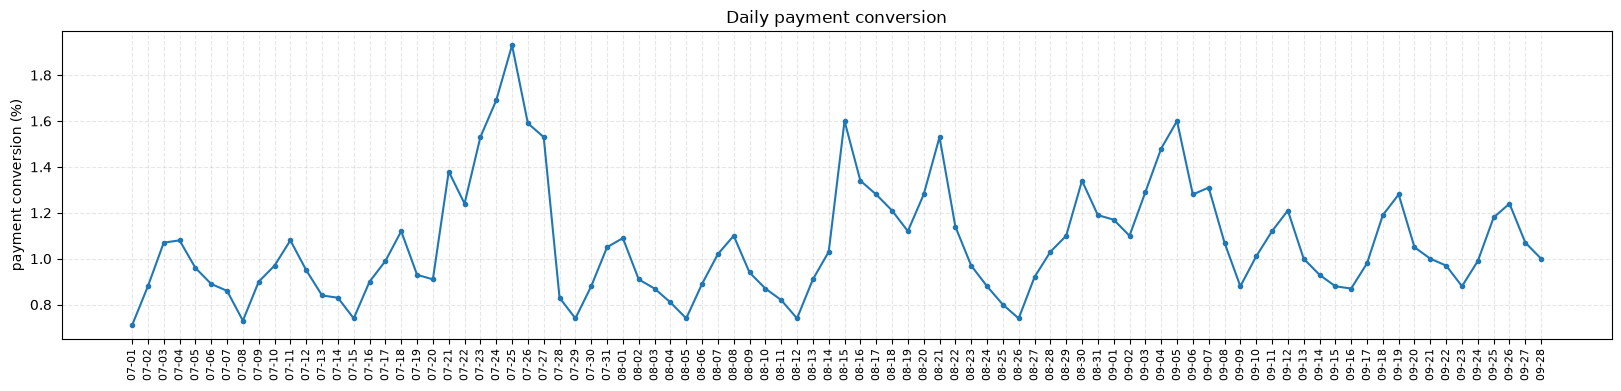

In [39]:
# 시각화
fig, ax = plt.subplots(figsize=(20, 4))

ax.plot(pay_conv_daily["date"], pay_conv_daily["pay_conv_pct"], marker="o", markersize=3)
ax.set_title("Daily payment conversion")
ax.set_ylabel("payment conversion (%)")
ax.grid(alpha=0.3, linestyle="--")

ax.set_xticks(pay_conv_daily["date"])
ax.set_xticklabels(pay_conv_daily["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

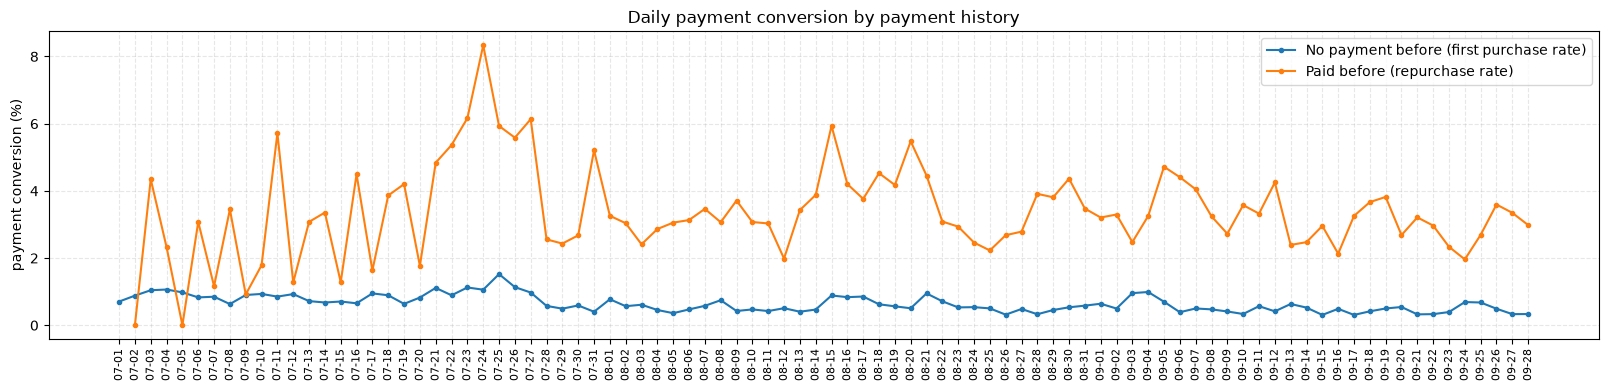

In [40]:
# 일별 결제 전환율: 그날 이전 결제 경험이 없는 유저 vs 있는 유저

# 유저별 첫 결제일
first_pay = payments.groupby("user_id")["paid_at"].min().dt.normalize()

# 접속 기록과 결제 기록에 "그날 이전에 결제한 적이 있는지" 표시 (결제 이력이 없으면 NaT라 False)
active_before = (daily["user_id"].map(first_pay) < daily["date"]).rename("paid_before")
pay_before = (payments["user_id"].map(first_pay) < pay_date).rename("paid_before")

# 일별, 그룹별 DAU와 결제 유저 수 (열: False = 비과금, True = 과금 경험 있음)
dau_group = daily.groupby(["date", active_before])["user_id"].nunique().unstack(fill_value=0)
payers_group = payments.groupby([pay_date, pay_before])["user_id"].nunique().unstack(fill_value=0)

# 그룹별 전환율(%)
conv_group = payers_group.reindex_like(dau_group).fillna(0) / dau_group * 100

# 시각화
fig, ax = plt.subplots(figsize=(20, 4))

ax.plot(conv_group.index, conv_group[False], marker="o", markersize=3, label="No payment before (first purchase rate)")
ax.plot(conv_group.index, conv_group[True], marker="o", markersize=3, label="Paid before (repurchase rate)")
ax.set_title("Daily payment conversion by payment history")
ax.set_ylabel("payment conversion (%)")
ax.legend()
ax.grid(alpha=0.3, linestyle="--")

# x축: 일자별 눈금, 90도 회전
ax.set_xticks(conv_group.index)
ax.set_xticklabels(conv_group.index.strftime("%m-%d"), rotation=90, fontsize=8)

plt.show()

In [41]:
# 프로모션 아닌 기간 vs 프로모션 기간별 일평균 결제 전환율 (결제 경험 유무별)

# 열 이름을 알아보기 쉽게 변경 (False = 비과금, True = 과금 경험 있음)
conv_s = conv_group.rename(columns={False: "nonpayer", True: "payer"})

rows = []

# 프로모션 아닌 기간
rows.append({
    "구분": "프로모션 아닌 기간",
    "기간": "그 외 기간",
    "첫 결제 전환율(%)": conv_s.loc[non_promo_mask, "nonpayer"].mean(),
    "재결제율(%)": conv_s.loc[non_promo_mask, "payer"].mean()
})

# 프로모션 및 업데이트 기간별
for name, (start, end) in periods.items():
    in_period = (conv_s.index >= pd.Timestamp(start)) & (conv_s.index <= pd.Timestamp(end))

    rows.append({
        "구분": name,
        "기간": f"{start[5:]} ~ {end[5:]}",
        "첫 결제 전환율(%)": conv_s.loc[in_period, "nonpayer"].mean(),
        "재결제율(%)": conv_s.loc[in_period, "payer"].mean()
    })

conv_by_period = pd.DataFrame(rows).set_index("구분")

# 프로모션 아닌 기간(평시) 대비 증감률(%)
base_first = conv_by_period.loc["프로모션 아닌 기간", "첫 결제 전환율(%)"]
base_repeat = conv_by_period.loc["프로모션 아닌 기간", "재결제율(%)"]

conv_by_period["첫 결제 평시 대비(%)"] = ((conv_by_period["첫 결제 전환율(%)"] / base_first - 1) * 100).round(1)
conv_by_period["재결제 평시 대비(%)"] = ((conv_by_period["재결제율(%)"] / base_repeat - 1) * 100).round(1)

# 표시할 때만 소수점과 부호 적용 (값은 숫자 그대로)
display(conv_by_period.style.format({
    "첫 결제 전환율(%)": "{:.2f}",
    "재결제율(%)": "{:.2f}",
    "첫 결제 평시 대비(%)": "{:+.1f}%",
    "재결제 평시 대비(%)": "{:+.1f}%"
}))

,기간,첫 결제 전환율(%),재결제율(%),첫 결제 평시 대비(%),재결제 평시 대비(%)
구분,,,,,
프로모션 아닌 기간,그 외 기간,0.65,2.84,+0.0%,+0.0%
여름 축제 1부,07-21 ~ 07-27,1.12,6.05,+72.1%,+112.9%
여름 축제 2부,08-15 ~ 08-21,0.75,4.65,+14.9%,+63.5%
성장 개편 업데이트 이후 핫픽스 전,08-30 ~ 09-07,0.64,3.69,-0.8%,+30.0%
핫픽스일,09-08 ~ 09-08,0.47,3.24,-27.1%,+14.1%
복귀 지원 이벤트,09-09 ~ 09-15,0.46,3.10,-29.6%,+9.1%
복귀 지원 이벤트 종료 후,09-16 ~ 09-28,0.45,2.97,-30.9%,+4.6%


### **요점**
- **여름 축제 기간 결제 전환율**: 결제 경험이 있는 유저(재결제율)의 상승폭이 비과금 유저(첫 결제 전환율)보다 큼.
    - ARPU 상승에는 두 집단 모두 기여했지만, 결제 경험이 있는 유저의 영향이 더 큰 것으로 보임.
- **한계점**: 결제 데이터는 7/1부터 있어서, 그 전에 결제한 유저는 비과금으로 분류될 수 있음.

## 8. 일별 플레이타임, 골드, 아이템
**분석 대상**: 해당 일자에 접속한 계정

In [42]:
# 일별 플레이타임, 골드 획득량, 아이템 획득량 평균·중앙값
daily_stats = (daily.groupby("date")
    .agg(active_users=("user_id", "nunique"),
         avg_playtime_min=("playtime_min", "mean"),
         median_playtime_min=("playtime_min", "median"),
         avg_gold=("gold_earned", "mean"),
         median_gold=("gold_earned", "median"),
         avg_items=("items_acquired", "mean"),
         median_items=("items_acquired", "median"))
    .round({"avg_playtime_min": 2, "median_playtime_min": 2,
            "avg_gold": 0, "median_gold": 0,
            "avg_items": 1, "median_items": 1})
    .reset_index())

daily_stats.head()

,date,active_users,avg_playtime_min,median_playtime_min,avg_gold,median_gold,avg_items,median_items
0,2026-07-01,2410,215.46,147.60,"34,177.00","23,748.00",53.50,19.00
1,2026-07-02,2619,210.59,149.00,"35,251.00","24,127.00",51.40,20.00
2,2026-07-03,2516,216.50,151.85,"35,778.00","25,385.00",52.80,19.00
3,2026-07-04,2862,212.92,160.65,"35,523.00","26,324.00",50.10,20.00
4,2026-07-05,2818,217.55,163.35,"37,256.00","26,924.00",50.80,21.00


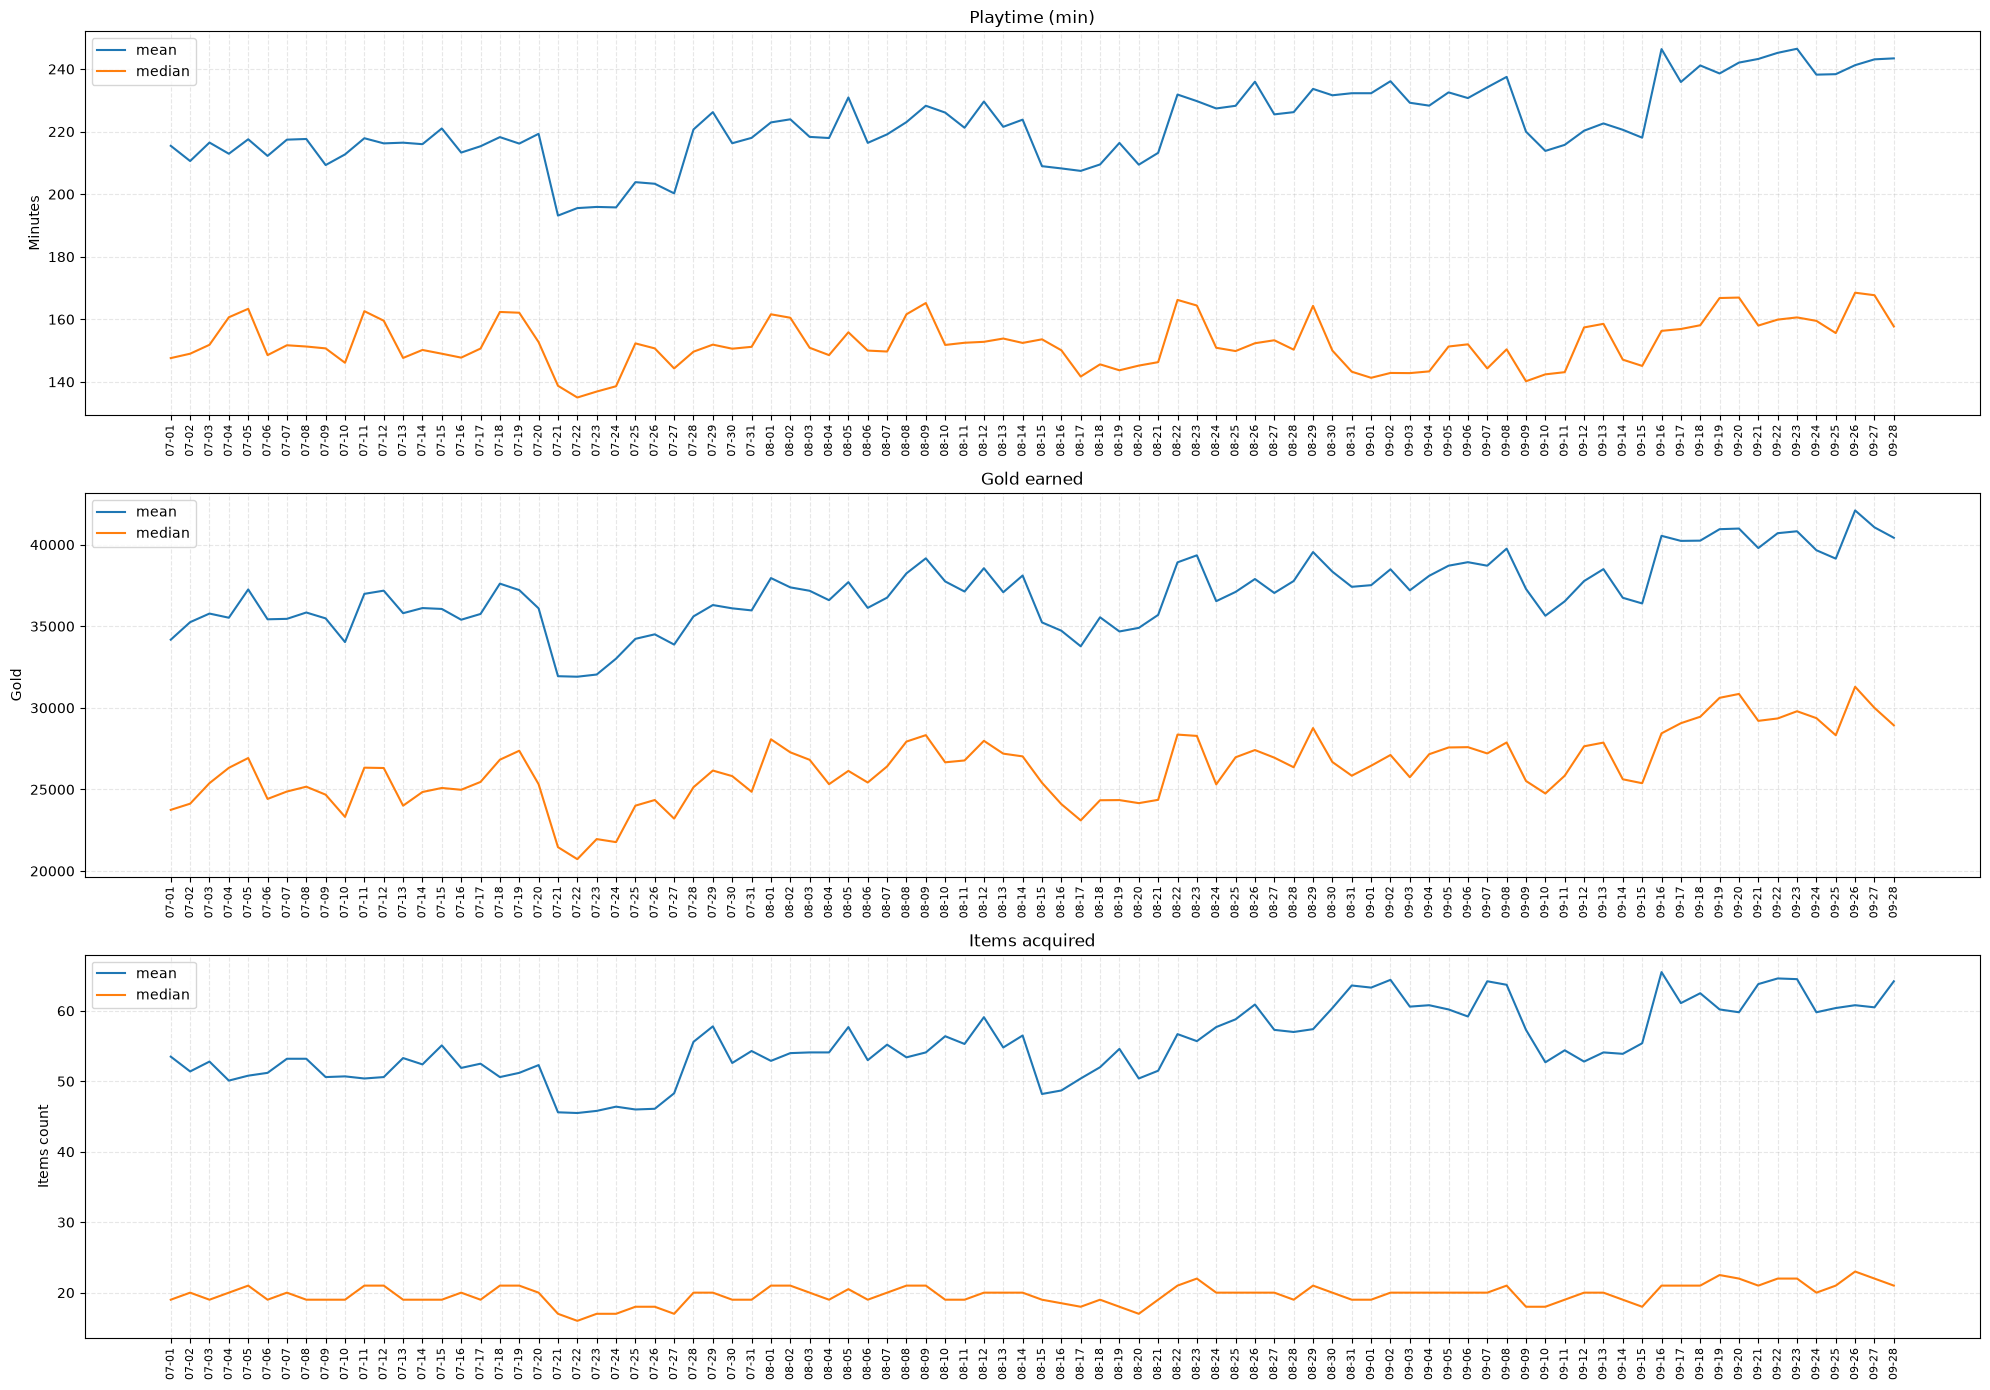

In [43]:
metrics = [
    ("playtime_min", "Playtime (min)", "Minutes"),
    ("gold", "Gold earned", "Gold"),
    ("items", "Items acquired", "Items count"),
]

plt.figure(figsize=(20, 14))

for i, (name, label, ylabel) in enumerate(metrics, start=1):
    ax = plt.subplot(3, 1, i)
    ax.plot(daily_stats["date"], daily_stats[f"avg_{name}"], label="mean")
    ax.plot(daily_stats["date"], daily_stats[f"median_{name}"], label="median")
    ax.set_title(label)
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3, linestyle="--")

    ax.set_xticks(daily_stats["date"])
    ax.set_xticklabels(daily_stats["date"].dt.strftime("%m-%d"), rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

### **요점**
- **프로모션 기간**: 평균 플레이타임, 골드 획득량, 아이템 획득량이 여름 축제 1부(7/21~7/27), 2부(8/15~8/21), 복귀 지원 이벤트(9/9~9/15) 기간에 낮았음.
    - 여름 축제 기간에는 신규 유저가 많이 유입되었고, 복귀 지원 이벤트 기간에는 복귀 유저가 늘어, 이들의 영향일 가능성이 있음.
    - 신규, 기존, 복귀 유저별 비율은 별도 프로모션 분석 노트북에서 확인 예정.
- **평균과 중앙값의 차이**: 플레이타임, 골드 획득량, 아이템 획득량 모두 평균과 중앙값의 차이가 큼.
    - 소수 헤비 유저의 영향일 수도 있으나, 봇이나 어뷰저의 영향일 가능성도 있음.
    - 어뷰저 의심 계정을 제외한 분석은 별도 어뷰저 분석 노트북에서 진행 예정.

## 요약
### 데이터
- 가상 MMORPG **Astrasia Online**의 2026-07-01 ~ 09-28(90일) 데이터를 `user_id` 단위로 분석함. (전체 유저 34,000명, 이 중 기간 내 신규 가입 6,000명)
- **유저 구성**: 국가는 KR 45.0%, JP 20.3%, US 17.6%, TW 10.0%, OTHER 7.1%. 플랫폼은 PC 60.5%, Mobile 39.5%.
- **다계정**: 기기 175대(전체의 0.5%)에서 909개 계정이 쓰이고 있으며, 기기 하나에 최대 28개 계정이 있음.

### 활성 유저 (DAU)
- 평시 일평균 DAU는 2,825명. **여름 축제 1부 +27.9%, 2부 +23.8%** 로 분석 기간 중 반응이 가장 컸음.
- **성장 개편 업데이트(8/30) ~ 핫픽스(9/8) 전**: 평시 대비 **-3.4%** 로 감소. 이후 복귀 지원 이벤트 기간(9/9 ~ 9/15)에 +19.5%로 회복했고, 종료 후에도 +4.0%(일 3,000명 전후)를 유지함.
    - 핫픽스 다음 날 복귀 지원 이벤트가 시작되어, DAU 회복이 핫픽스 때문인지 복귀 지원 이벤트 때문인지 구분이 어려움.

### 신규 유입과 리텐션
- 평시 일평균 신규 가입자는 51명. 여름 축제 1부 154명(+200.7%), 2부 152명(+196.8%)으로 약 3배 증가함.
- 가입 후 리텐션은 D1 38.6% → D14 9.8%로 28.8%p 떨어진 뒤, D30까지는 3.8%p만 감소함. 따라서 **D1, D3, D7, D14**를 핵심 마일스톤으로 정함.
- **여름 축제 가입 코호트**는 리텐션도 평시보다 높았음. (1부 D7 +5.61%p, D30 +2.31%p / 2부 D7 +2.93%p, D30 +1.09%p)
- **8/29 이후 가입 코호트**는 리텐션이 전반적으로 낮아짐. 업데이트 ~ 핫픽스 전 가입 코호트는 D1 -6.40%p, D7 -4.21%p로 가장 낮았음.

### 성장 퍼널
- 가입 후 40일 이상 지난 신규 유저 3,901명을 대상으로 분석. 그중 Lv30 도달은 24.9%.
- **`reach_lv10 → first_dungeon` 전환율이 43.7%**(1,804명 이탈)로 가장 낮은 병목 구간임.

### 매출
- 90일 총매출은 약 1억 1,834만 원(일평균 약 131만 원). 여름 축제 1, 2부의 일평균 매출은 평시 대비 +109.0%, +82.0%로, 두 기간 14일 동안 전체 매출의 24.3%가 발생함.
- 평시 일평균 ARPU는 370원, ARPPU는 40,476원. ARPPU는 프로모션, 이벤트 기간동안 평시 대비 -3.3% ~ +2.8%로 변동성이 낮아, **매출 변화는 결제하는 유저 수에 더 큰 영향을 받는 것으로 보임**.
- **여름 축제**: ARPU가 1부 +63.9%, 2부 +47.7% 상승함. 첫 결제 전환율(1부 +72.1%)보다 재결제율(1부 +112.9%)의 상승폭이 커, 결제 경험이 있는 유저의 매출 기여가 더 컸던 것으로 보임.
- **성장 개편 업데이트 ~ 핫픽스 전**: DAU는 줄었지만 ARPU는 +47.0% 상승함. 첫 결제 전환율은 평시와 비슷하고(-0.8%) 재결제율이 +30.0% 올라, 기존 과금 유저가 매출 상승을 이끈 것으로 보임.

### 플레이 지표와 데이터 품질
- 플레이타임(평균 222분 / 중앙값 152분), 골드, 아이템(평균 55개 / 중앙값 20개) 모두 평균이 중앙값보다 크게 높음. 위의 다계정 기기와 함께 **봇이나 어뷰저가 섞여 있을 가능성**이 있음.
- 프로모션 기간에는 평균 플레이 지표가 낮았는데, 플레이량이 적은 신규, 복귀 유저가 늘어난 영향으로 추정됨.

### 한계점
- 여름 축제의 유입 효과가 콘텐츠 때문인지 같은 기간 마케팅 때문인지 구분할 수 없음.
- 결제 데이터가 7/1부터 있어 그 전에 결제 경험이 있는 유저가 비과금으로 분류될 수 있음.

### 다음 분석
- **프로모션 분석 노트북**: 신규, 기존, 복귀 유저별 프로모션 효과와 핫픽스 효과를 구분함.
- **어뷰저 분석 노트북**: 다계정 기기와 비정상 플레이 지표를 기준으로 의심 계정을 탐지하고, 이를 제외한 지표를 다시 확인함.